In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".08"
import numpy as np
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer
from skophys.sm import NNCCA, NNSM
from skophys.datasets import ARProcessMovie
from sklearn.metrics.pairwise import cosine_similarity
from skimage.transform import downscale_local_mean
from scipy.optimize import linear_sum_assignment
from ipywidgets import HBox, VBox
import fastplotlib as fpl
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
import seaborn as sns
from itertools import product

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
%matplotlib inline

In [3]:
from tqdm import tqdm
import pandas as pd

In [4]:
noise_options = np.linspace(0, 5, num=26)
noise_options

array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. , 2.2, 2.4,
       2.6, 2.8, 3. , 3.2, 3.4, 3.6, 3.8, 4. , 4.2, 4.4, 4.6, 4.8, 5. ])

In [5]:
datasets = ["simple"]
noise_options = np.linspace(0, 5, num=26)
methods = {"nnSM": NNSM}
# methods = {"nnSM": NNSM, "nnCCA": NNCCA}
lags = [1, 2, 4, 6, 8]
rand_seeds = range(24)

all_locs = np.array(list(product(range(5), range(5))))

df = pd.DataFrame(columns=["dataset", "noise", "method", "lag", "cs_trace", "rand-seed"])

for dataset in datasets:
    for noise_sigma in tqdm(noise_options):
        for method in methods.keys():
            for lag in lags:
                for rand_seed in rand_seeds:
                    if dataset == "simple":
                        locs = np.array([
                            [0, 0],
                            [2, 0]
                        ])
                        
                        ar_model = ARProcessMovie(
                            n_timepoints=5000,
                            n_components=2,
                            ar_noise_sigma=0.1,
                            obs_noise_sigma=noise_sigma,
                            random_seed=rand_seed,
                            movie_dims=(10, 15),
                            component_locs=locs,
                            firing_probability=0.02
                        )
                        
                        movie = ar_model.movie
                    elif dataset == "complex":
                        np.random.seed(rand_seed)
                        locs = all_locs[np.random.choice(all_locs.shape[0], size=7, replace=False)]
                        
                        ar_model = ARProcessMovie(
                            n_timepoints=5000,
                            n_components=locs.shape[0],
                            random_seed=rand_seed,
                            ar_noise_sigma=0.1,
                            obs_noise_sigma=noise_sigma,
                            movie_dims=(15, 15),
                            component_locs=locs,
                            firing_probability=0.01
                        )
                        
                        movie = ar_model.movie
    
                    model = methods[method](lag=lag, lag_step=1)
    
                    n_init = 1_000
    
                    if method == "nnCCA":
                        model.pre_initialize(movie[:n_init], max_k=ar_model.traces.shape[0], k=ar_model.traces.shape[0], print_progress=False, method="nnsvd", whiten_method="half-trunc")
                        half_lag = int(model.lag)
                    else:
                        model.pre_initialize(movie[:n_init], max_k=ar_model.traces.shape[0], k=ar_model.traces.shape[0], print_progress=False, method="nnsvd")
                        half_lag = int(model.lag / 2)
                    
                    err_log, Ys, Ws = model.initialize(max_iter=20_000, keep_iteration_results=True, eta=0.05, inertia=1e-3, error_threshold=0.001, progress_bar=False)
                    
                    if model.lag > 1:
                        permute_ixs, cos_sim = model.permute_indices(ar_model.traces[:, half_lag:n_init - half_lag])    
                    else:
                        permute_ixs, cos_sim = model.permute_indices(ar_model.traces[:, 1: 1 + model.init_arrays.Y.shape[1]])
                        
                    tr = np.trace(cos_sim)
    
                    df.loc[df.index.size] = pd.Series(
                        {
                            "dataset": dataset,
                            "noise": noise_sigma,
                            "method": method,
                            "lag": lag,
                            "cs_trace": tr / ar_model.traces.shape[0],
                            "rand-seed": rand_seed,
                            "Y": model.init_arrays.Y,
                            "W": model.init_arrays.W,
                            "M": model.init_arrays.M,
                            "truth-temporal": ar_model.traces,
                            "lag": model.lag,
                            "k": model.init_arrays.k,
                            "truth-spatial": ar_model.spatial,
                        }
                    )

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 26/26 [21:31<00:00, 49.68s/it]


In [6]:
df

,dataset,noise,method,lag,cs_trace,rand-seed
0,complex,0.0,nnSM,1,0.92054,0
1,complex,0.0,nnSM,1,0.913263,1
2,complex,0.0,nnSM,1,0.903571,2
3,complex,0.0,nnSM,1,0.920893,3
4,complex,0.0,nnSM,1,0.928352,4
...,...,...,...,...,...,...
1295,complex,5.0,nnSM,8,0.339986,5
1296,complex,5.0,nnSM,8,0.363074,6
1297,complex,5.0,nnSM,8,0.3353,7
1298,complex,5.0,nnSM,8,0.382416,8


In [6]:
df.columns

Index(['dataset', 'noise', 'method', 'lag', 'cs_trace', 'rand-seed'], dtype='object')

In [7]:
sns.set(font_scale=1.2)

Text(0.5, 1.0, '2 cells')

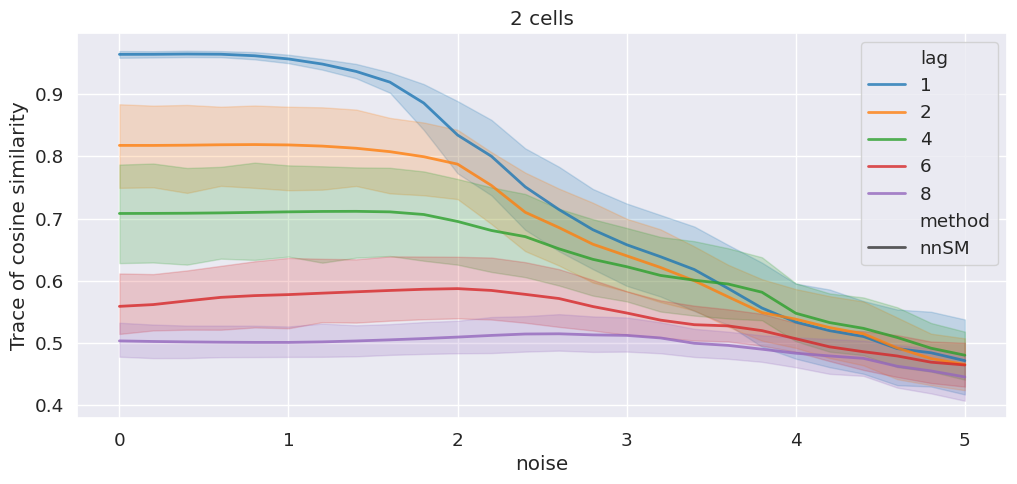

In [11]:
fig = plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df[df["dataset"] == "simple"],
    x="noise",
    y="cs_trace",
    hue="lag",
    palette="tab10",
    style="method",
    linewidth=2,
    alpha=0.8,
)
plt.ylabel("Trace of cosine similarity")
plt.title("2 cells")

Text(0.5, 1.0, '7 cells')

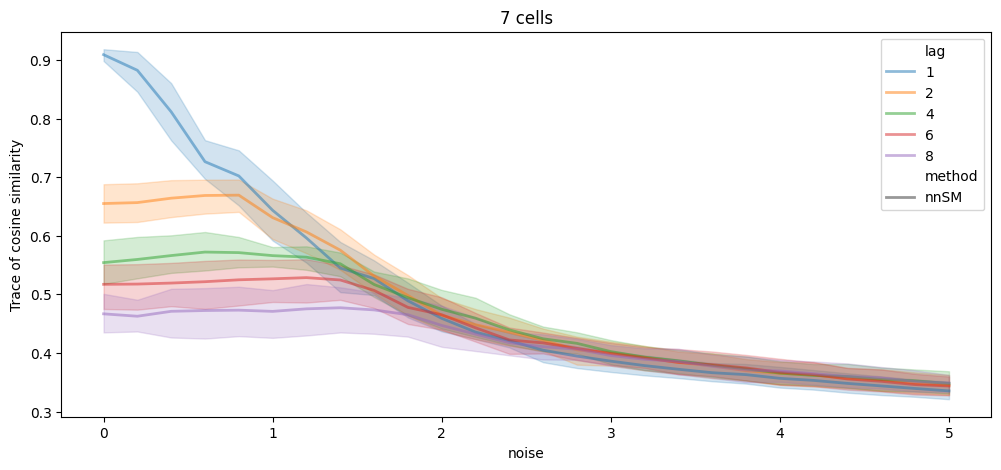

In [10]:
fig = plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df[df["dataset"] == "complex"],
    x="noise",
    y="cs_trace",
    hue="lag",
    palette="tab10",
    style="method",
    linewidth=2,
    alpha=0.5,
)
plt.ylabel("Trace of cosine similarity")
plt.title("7 cells")